,Gender,Polyuria_No,Polyuria_Yes,Polydipsia_No,Polydipsia_Yes,sudden weight loss_No,sudden weight loss_Yes,weakness_No,weakness_Yes,Polyphagia_No,...,partial paresis_No,partial paresis_Yes,muscle stiffness_No,muscle stiffness_Yes,Alopecia_No,Alopecia_Yes,Obesity_No,Obesity_Yes,class_Negative,class_Positive
0,Male,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
1,Male,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,Male,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,Male,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
4,Male,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,Female,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
516,Female,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
517,Female,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
518,Female,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


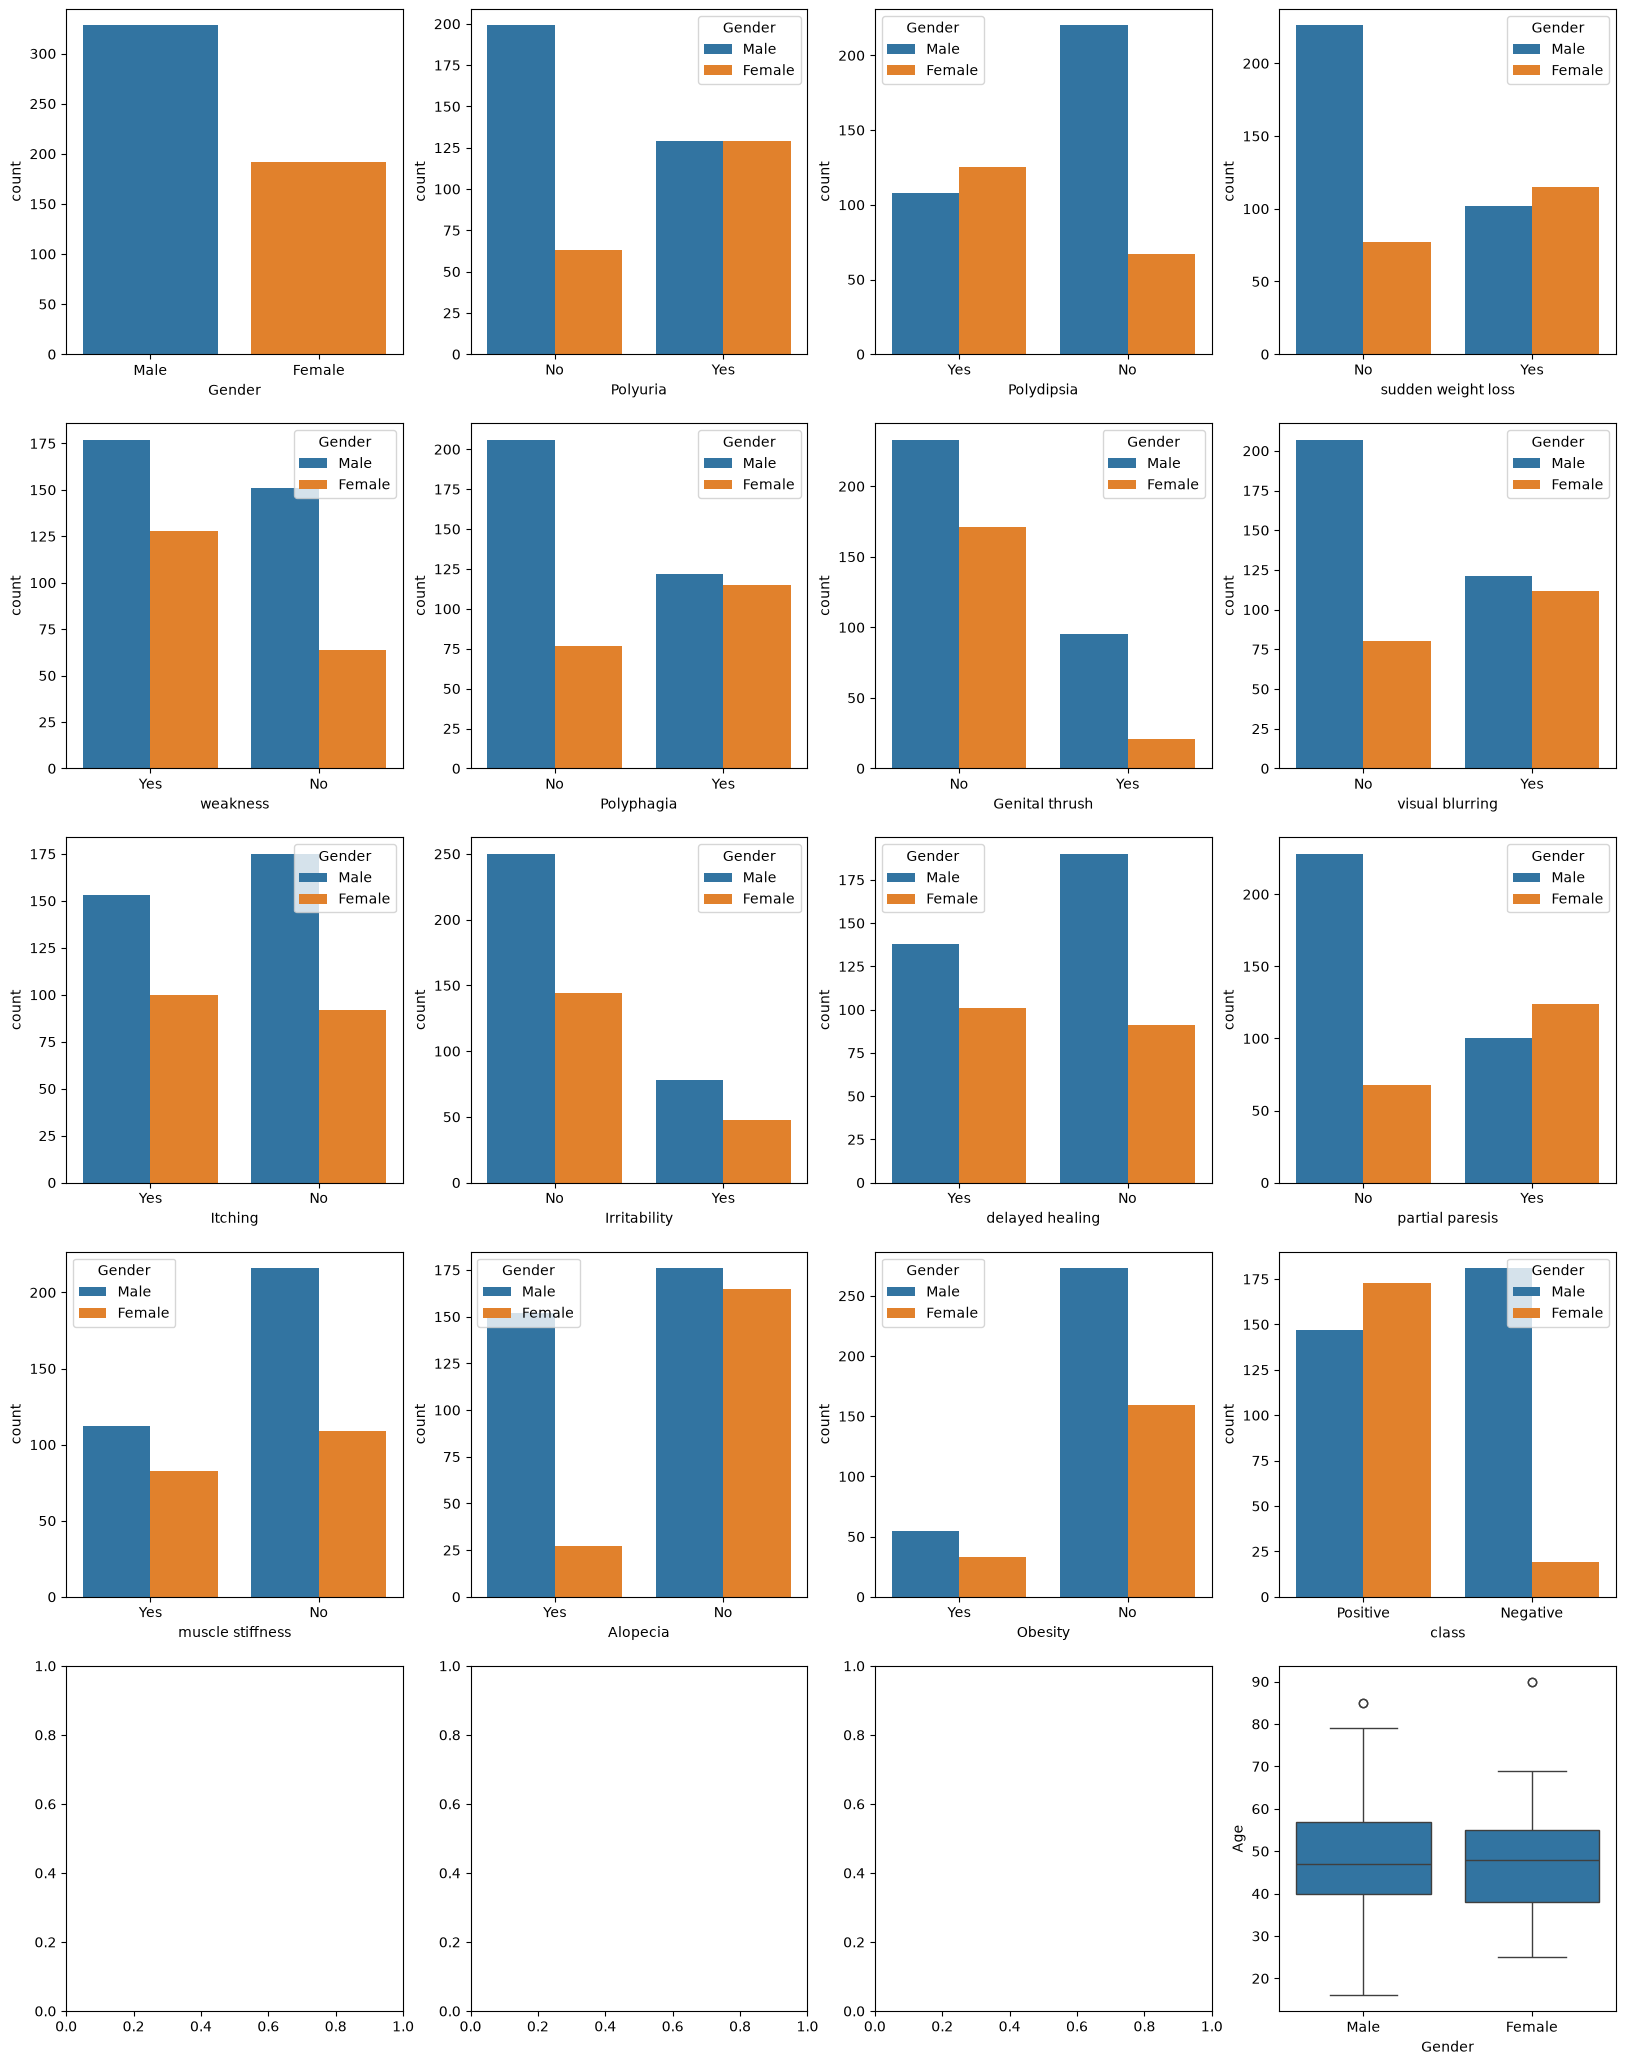

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

def process_categorical_data():
	# Starting with classification dataset
	class_df = pd.read_csv("cw1/diabetes_data_upload.csv", index_col=False)
	# class_df.head()
	#class_df.info()
	# No Null values are in this dataset
	# print(class_df.isnull().sum())

	# Visualise and then handle outliers
	# Our diabetes dataset contains symptoms so uncommon symptoms may not indicate the condition

	features = class_df.iloc[:,1:]
	fig,axes = plt.subplots(5,4,figsize=(20,26))

	sns.boxplot(x="Gender", y="Age", data=class_df)
	# sns.countplot(x="Gender", data=class_df)
	# sns.countplot(x="Polyuria", data=class_df, hue="Gender")
	for	feature, ax in zip(features, axes.flat):
		sns.countplot(x=feature, data=class_df, ax=ax, hue="Gender")

	plt.show
	# Seems that there are 2 outliers for age, since we only care about categorical data we will drop this column

	class_df = class_df.drop(columns="Age")
	# Chose to One hot encode instead of ordinal because it suits our binary data better
	cat_encoder = OneHotEncoder(sparse_output=False)
	# We are only going to encode our feature because our label needs to be a 1d array
	cdf_encoded = cat_encoder.fit_transform(class_df.iloc[:,1:])


	encoded_df_diabetes = pd.DataFrame( # recreate the df with new column names
		cdf_encoded,
		columns=cat_encoder.get_feature_names_out(),
		index=class_df.index)

	encoded_df_diabetes = pd.concat([class_df["Gender"], encoded_df_diabetes], axis=1)
	# You don't need to convert the label actually xd
	#https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/

	return encoded_df_diabetes

process_categorical_data()